In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [3]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [5]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [4]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [6]:
len(feature_cols)

20

In [7]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [8]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [9]:
len(df_sig_85), len(df_bkg_85), len(df_sig_70), len(df_bkg_70)

# WP 70: 323900, 3959 


(358887, 5855, 323900, 3959)

In [78]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


In [79]:
print('For tty prod NLO (prompts at 85 and 70): ', len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70))
print('For tty prod NLO (fakes at 85 and 70): ', len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70))

print('For tty dec LO (prompts at 85 and 70): ', len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70))
print('For tty dec LO (fakes at 85 and 70): ', len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70))


print('For Wyy (prompts at 85 and 70): ',len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70))
print('For Wyy (fakes at 85 and 70): ',len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70))
print('For Zyy (prompts at 85 and 70): ',len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70))
print('For Zyy (fakes at 85 and 70): ',len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70))

For tty prod NLO (prompts at 85 and 70):  222 203
For tty prod NLO (fakes at 85 and 70):  1928 1748
For tty dec LO (prompts at 85 and 70):  141 126
For tty dec LO (fakes at 85 and 70):  1036 942
For Wyy (prompts at 85 and 70):  368 130
For Wyy (fakes at 85 and 70):  0 0
For Zyy (prompts at 85 and 70):  2073 774
For Zyy (fakes at 85 and 70):  87 36


In [80]:
data = [
    ["tty prod NLO", "Prompts", len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70),len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)],
    ["tty prod NLO", "Fakes", len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70),len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)],
    ["tty dec LO", "Prompts", len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70),len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)],
    ["tty dec LO", "Fakes", len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70),len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)],
    ["Wyy", "Prompts", len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70),len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)],
    ["Wyy", "Fakes", len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70),'NA'],
    ["Zyy", "Prompts", len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70),len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)],
    ["Zyy", "Fakes", len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70),len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)],
]

# Print the data in a tabular format
print(f"{'Process':<15} {'Type':<10} {'85 Cut':<10} {'70 Cut':<10} {'Scaling 70/85':<5}")
print("-" * 65)
for row in data:
    scaling = f"{row[4]:.3f}" if row[4] != 'NA' else row[4]
    print(f"{row[0]:<15} {row[1]:<10} {row[2]:<10} {row[3]:<10} {scaling:<5}")

print("-" * 65)

print(f"{'Total:':<25} {len(df_bkg_85):<10} {len(df_bkg_70):<10}")

Process         Type       85 Cut     70 Cut     Scaling 70/85
-----------------------------------------------------------------
tty prod NLO    Prompts    222        203        0.914
tty prod NLO    Fakes      1928       1748       0.907
tty dec LO      Prompts    141        126        0.894
tty dec LO      Fakes      1036       942        0.909
Wyy             Prompts    368        130        0.353
Wyy             Fakes      0          0          NA   
Zyy             Prompts    2073       774        0.373
Zyy             Fakes      87         36         0.414
-----------------------------------------------------------------
Total:                    5855       3959      


In [15]:
df_bkg_fakes_70_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_70, df_bkg_fakes_ttydecLO_70, df_bkg_fakes_Wyy_70, df_bkg_fakes_Zyy_70], ignore_index=False)
df_bkg_prompt_70_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_70, df_bkg_prompt_ttydecLO_70, df_bkg_prompt_Wyy_70, df_bkg_prompt_Zyy_70], ignore_index=False)


In [16]:
print(len(df_bkg_fakes_70_reweighted), len(df_bkg_prompt_70_reweighted))

2726 1233


# Training with WP70

In [74]:
n_estimators = 33

In [75]:
# change

nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    
    print(f"\nFold: {fold}")
    
    X_sig_train = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_70_reweighted[feature_cols][df_bkg_prompt_70_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_70_reweighted['weight'][df_bkg_prompt_70_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_70_reweighted[feature_cols][df_bkg_prompt_70_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_70_reweighted['weight'][df_bkg_prompt_70_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_70_reweighted[feature_cols][df_bkg_fakes_70_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_70_reweighted['weight'][df_bkg_fakes_70_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_70_reweighted[feature_cols][df_bkg_fakes_70_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_70_reweighted['weight'][df_bkg_fakes_70_reweighted['eventNumber']%nfolds == fold]

 
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    
    print("\n\n\nSignal train & test sizes (events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Prompt train test sizes (events,weights): ", len(X_bkg_train_prompts), len(w_bkg_train_prompts),  len(X_bkg_test_prompts), len(w_bkg_test_prompts))
    print("Fake train test sizes (events,weights): ", len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_fakes), len(w_bkg_test_fakes))

    #print(f"Fold {fold}:")
    #print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    #print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    print(f"\n\nFold {fold}:")
    print(f"Signal: {len(X_sig_train)} train, {len(X_sig_test)} test")
    print(f"Prompt Background: {len(X_bkg_train_prompts)} train, {len(X_bkg_test_prompts)} test")
    print(f"Fake Background: {len(X_bkg_train_fakes)} train, {len(X_bkg_test_fakes)} test")

    print(f"Class 0 (Signal): Train = {np.sum(y_train == 0)}, Test = {np.sum(y_test == 0)}")
    print(f"Class 1 (Prompt Background): Train = {np.sum(y_train == 1)}, Test = {np.sum(y_test == 1)}")
    print(f"Class 2 (Fake Background): Train = {np.sum(y_train == 2)}, Test = {np.sum(y_test == 2)}")
    
    # Check weight sums
    print(f"Total training weight: {np.sum(w_train)}, Total testing weight: {np.sum(w_test)}")
    print(f"Class 0 weight sum: Train = {np.sum(w_train[y_train == 0])}, Test = {np.sum(w_test[y_test == 0])}")
    print(f"Class 1 weight sum: Train = {np.sum(w_train[y_train == 1])}, Test = {np.sum(w_test[y_test == 1])}")
    print(f"Class 2 weight sum: Train = {np.sum(w_train[y_train == 2])}, Test = {np.sum(w_test[y_test == 2])}")
    
    
    #Checking for nans and infs
    print(f"\nChecking Fold {fold} for NaNs/Infs...")
    print(f"X_train NaNs: {np.isnan(X_train).sum()}, X_train Infs: {np.isinf(X_train).sum()}")
    print(f"X_test NaNs: {np.isnan(X_test).sum()}, X_test Infs: {np.isinf(X_test).sum()}")
    print(f"y_train NaNs: {np.isnan(y_train).sum()}, y_train Infs: {np.isinf(y_train).sum()}")
    print(f"y_test NaNs: {np.isnan(y_test).sum()}, y_test Infs: {np.isinf(y_test).sum()}")


    
    #Checking 
    print(f"\nChecking Fold {fold} class distributions:")
    print(f"Unique classes in training: {np.unique(y_train)}")
    print(f"Unique classes in testing: {np.unique(y_test)}")
    
    # Initialize XGBoost model for multi-class classification
    #model = XGBClassifier(objective='multi:softmax', num_class=3, use_label_encoder=False)
    #Set 1 of model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)

    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        #objective="multi:softmax",  # Objective for multi-class classification
        #num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
    
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print(n_boosters)
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_3ClassWP85To70_Model8_Fold{fold}_60boosters.pkl', 'wb') as f:
    #    pickle.dump(model, f)
                       



Fold: 0



Signal train & test sizes (events,weights):  243054 243054 80846 80846
Prompt train test sizes (events,weights):  925 925 308 308
Fake train test sizes (events,weights):  2052 2052 674 674


Fold 0:
Signal: 243054 train, 80846 test
Prompt Background: 925 train, 308 test
Fake Background: 2052 train, 674 test
Class 0 (Signal): Train = 243054, Test = 80846
Class 1 (Prompt Background): Train = 925, Test = 308
Class 2 (Fake Background): Train = 2052, Test = 674
Total training weight: 53.569820404052734, Total testing weight: 18.773780822753906
Class 0 weight sum: Train = 30.664501190185547, Test = 10.214448928833008
Class 1 weight sum: Train = 5.984489440917969, Test = 3.238729238510132
Class 2 weight sum: Train = 16.92082977294922, Test = 5.320601463317871

Checking Fold 0 for NaNs/Infs...
X_train NaNs: 0, X_train Infs: 0
X_test NaNs: 0, X_test Infs: 0
y_train NaNs: 0, y_train Infs: 0
y_test NaNs: 0, y_test Infs: 0

Checking Fold 0 class distributions:
Unique classes in trainin

In [23]:
mplhep.style.use('ATLAS')    


In [76]:
# Testing loss curve - 06.02.2025

###############################

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)
print(len(X_train))
print(len(X_test))


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        #print(len(ypred_train),len(ypred_test))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)
    print(f"Fold {fold} >")
    print(trainloss[fold])
    print(testloss[fold])


99
245762
82097
Fold 0 >
[1.030082908195339, 0.9847284133660071, 0.9521420001317984, 0.9275316066380284, 0.9100566939891478, 0.8963778802140185, 0.8848538967466351, 0.8754647129938241, 0.868044750980749, 0.8613949328977788, 0.8563307788702712, 0.8509616047031581, 0.8448486278693087, 0.8402403310998003, 0.8362641925151487, 0.8331734106106625, 0.8304079498640529, 0.8277131728957994, 0.8231744490410877, 0.8212848779116798, 0.8192974824078718, 0.8174601007757178, 0.8149073229098132, 0.8113161383172441, 0.8095068656446958, 0.8076674391053477, 0.804998812956452, 0.80369358926212, 0.8013192269022438, 0.7992634671636613, 0.7974914171186718, 0.7963790870678545, 0.7947016752807213]
[1.025768186255913, 0.9759075976505338, 0.9385764940659261, 0.9093337436155616, 0.887922374439263, 0.8711897884237488, 0.8564834666455177, 0.8458448426934557, 0.8350451044302684, 0.8248769277869457, 0.8163425394834246, 0.8083665461706895, 0.8003732579463577, 0.7943982266843438, 0.7879743277454185, 0.7818642574399426, 

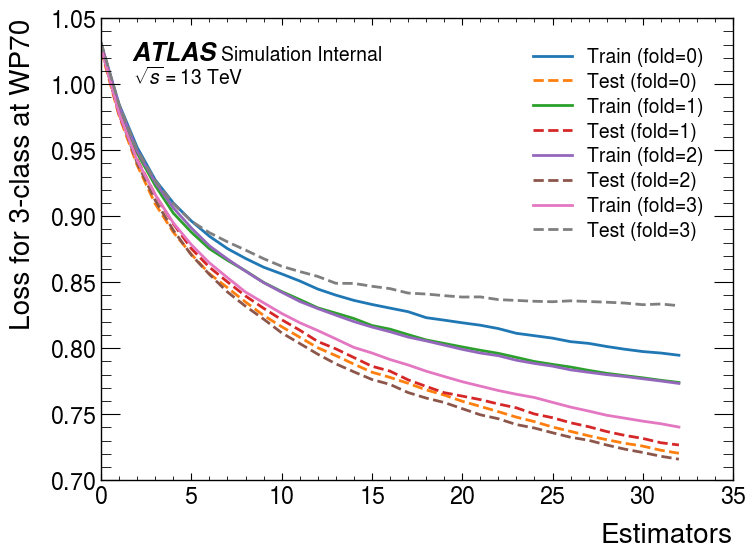

In [77]:
nfolds = 4
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for 3-class at WP70')
plt.show()

# Training with WP85

In [13]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [44]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [82]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [81]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

2804

In [83]:
print(df_bkg_prompt_85_reweighted['weight'].describe())

count    2804.000000
mean        0.008136
std         0.028790
min        -0.221152
25%         0.000259
50%         0.001254
75%         0.007002
max         0.768141
Name: weight, dtype: float64


In [84]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [49]:
print(df_bkg_fakes_85_reweighted['weight'].describe())

count    3051.000000
mean        0.007310
std         0.013094
min        -0.029860
25%         0.003973
50%         0.009968
75%         0.017414
max         0.046421
Name: weight, dtype: float64


In [18]:
#df_bkg_85_reweighted = pd.concat([df_bkg_prompt_85_reweighted, df_bkg_fakes_85_reweighted], ignore_index=False)

In [19]:
#len(df_bkg_85_reweighted)

In [50]:
mplhep.style.use('ATLAS')

# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics) -> No, doesn't work.. 
# No scale pos parameter can be added

In [271]:
df_sig_85_reweighted = df_sig_85

In [43]:
df_sig_85['eventNumber'].describe()


count    3.588870e+05
mean     1.464455e+07
std      8.882928e+06
min      1.000000e+01
25%      6.599648e+06
50%      1.457924e+07
75%      2.246156e+07
max      2.999998e+07
Name: eventNumber, dtype: float64

In [240]:
df_sig_85['weight'].describe(), df_bkg_prompt_ttyprodNLO_85['weight'].describe(), df_bkg_prompt_ttydecLO_85['weight'].describe(), df_bkg_prompt_Wyy_85['weight'].describe(), df_bkg_prompt_Zyy_85['weight'].describe()

(count    358887.000000
 mean          0.000127
 std           0.000038
 min          -0.000170
 25%           0.000109
 50%           0.000133
 75%           0.000151
 max           0.000921
 Name: weight, dtype: float64,
 count    222.000000
 mean       0.007276
 std        0.015533
 min       -0.024470
 25%       -0.009675
 50%        0.014474
 75%        0.019296
 max        0.025153
 Name: weight, dtype: float64,
 count    141.000000
 mean       0.008035
 std        0.002463
 min        0.001153
 25%        0.006761
 50%        0.008403
 75%        0.009744
 max        0.014543
 Name: weight, dtype: float64,
 count    368.000000
 mean       0.014280
 std        0.024044
 min       -0.078124
 25%        0.002348
 50%        0.005400
 75%        0.015319
 max        0.271354
 Name: weight, dtype: float64,
 count    2073.000000
 mean        0.000883
 std         0.002664
 min        -0.008877
 25%         0.000078
 50%         0.000252
 75%         0.000800
 max         0.092987
 Nam

In [247]:
# Calculate the mean of negative values in the 'weight' column
mean_negative_weights = df_bkg_prompt_ttyprodNLO_85[df_bkg_prompt_ttyprodNLO_85['weight'] < 0]['weight'].mean()
print(f"Mean neg weight: {mean_negative_weights}")
# Filter and print values less than the mean of negative values
print(df_bkg_prompt_ttyprodNLO_85[df_bkg_prompt_ttyprodNLO_85['weight'] < mean_negative_weights]['weight'])

Mean neg weight: -0.01662091538310051
entry
9      -0.022078
83     -0.021166
260    -0.018622
338    -0.017801
367    -0.017680
388    -0.020688
566    -0.018782
610    -0.017201
647    -0.019527
648    -0.020789
655    -0.021562
657    -0.021676
736    -0.017103
776    -0.019143
822    -0.020182
871    -0.020217
942    -0.018658
1013   -0.018698
1135   -0.016926
1151   -0.020215
1172   -0.018751
1195   -0.016935
1226   -0.018617
1242   -0.019286
1278   -0.016622
1366   -0.020566
1384   -0.021682
1487   -0.021076
1493   -0.019236
1501   -0.024470
1506   -0.022665
1839   -0.019744
2141   -0.018903
Name: weight, dtype: float32


In [248]:
# Calculate the mean of negative values in the 'weight' column
mean_negative_weights = df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < 0]['weight'].mean()
print(f"Mean neg weight: {mean_negative_weights}")
# Filter and print values less than the mean of negative values
print(df_bkg_fakes_ttyprodNLO_85[df_bkg_fakes_ttyprodNLO_85['weight'] < mean_negative_weights]['weight'])

Mean neg weight: -0.01699763350188732
entry
0      -0.023602
1      -0.018001
17     -0.017715
25     -0.019851
29     -0.018626
          ...   
2130   -0.018008
2133   -0.022136
2137   -0.019714
2139   -0.017308
2144   -0.018256
Name: weight, Length: 320, dtype: float32


In [101]:
n_estimators = 40

In [133]:

nfolds = 4

# SINGLE MODEL  : Using XGB Classifier
models = []
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds-1, -1, -1):
 

    print(f"\nFold: {fold}")
    
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%nfolds == fold]
        
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%nfolds == fold]

 
    y_train =  np.concatenate([np.zeros_like(w_sig_train),np.ones_like(w_bkg_train_prompts),2 * np.ones_like(w_bkg_train_fakes)]) #putting classes 0, 1, 2
    X_train =  np.concatenate([X_sig_train,X_bkg_train_prompts,X_bkg_train_fakes])
    w_train =  np.concatenate([w_sig_train,w_bkg_train_prompts,w_bkg_train_fakes])
    y_test  =  np.concatenate([np.zeros_like(w_sig_test),np.ones_like(w_bkg_test_prompts),2 * np.ones_like(w_bkg_test_fakes)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test_prompts,X_bkg_test_fakes])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test_prompts,w_bkg_test_fakes])
    
    
    
    print("\n\n\nSignal train & test sizes (events,weights): ", len(X_sig_train), len(w_sig_train), len(X_sig_test), len(w_sig_test))
    print("Prompt train test sizes (events,weights): ", len(X_bkg_train_prompts), len(w_bkg_train_prompts),  len(X_bkg_test_prompts), len(w_bkg_test_prompts))
    print("Fake train test sizes (events,weights): ", len(X_bkg_train_fakes), len(w_bkg_train_fakes), len(X_bkg_test_fakes), len(w_bkg_test_fakes))

    #print(f"Fold {fold}:")
    #print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    #print(f"\nTesting: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    print(f"\n\nFold {fold}:")
    print(f"Signal: {len(X_sig_train)} train, {len(X_sig_test)} test")
    print(f"Prompt Background: {len(X_bkg_train_prompts)} train, {len(X_bkg_test_prompts)} test")
    print(f"Fake Background: {len(X_bkg_train_fakes)} train, {len(X_bkg_test_fakes)} test")

    print(f"Class 0 (Signal): Train = {np.sum(y_train == 0)}, Test = {np.sum(y_test == 0)}")
    print(f"Class 1 (Prompt Background): Train = {np.sum(y_train == 1)}, Test = {np.sum(y_test == 1)}")
    print(f"Class 2 (Fake Background): Train = {np.sum(y_train == 2)}, Test = {np.sum(y_test == 2)}")
    
    # Check weight sums
    print(f"Total training weight: {np.sum(w_train)}, Total testing weight: {np.sum(w_test)}")
    print(f"Class 0 weight sum: Train = {np.sum(w_train[y_train == 0])}, Test = {np.sum(w_test[y_test == 0])}")
    print(f"Class 1 weight sum: Train = {np.sum(w_train[y_train == 1])}, Test = {np.sum(w_test[y_test == 1])}")
    print(f"Class 2 weight sum: Train = {np.sum(w_train[y_train == 2])}, Test = {np.sum(w_test[y_test == 2])}")
    
    
    #Checking for nans and infs
    print(f"\nChecking Fold {fold} for NaNs/Infs...")
    print(f"X_train NaNs: {np.isnan(X_train).sum()}, X_train Infs: {np.isinf(X_train).sum()}")
    print(f"X_test NaNs: {np.isnan(X_test).sum()}, X_test Infs: {np.isinf(X_test).sum()}")
    print(f"y_train NaNs: {np.isnan(y_train).sum()}, y_train Infs: {np.isinf(y_train).sum()}")
    print(f"y_test NaNs: {np.isnan(y_test).sum()}, y_test Infs: {np.isinf(y_test).sum()}")


    
    #Checking 
    print(f"\nChecking Fold {fold} class distributions:")
    print(f"Unique classes in training: {np.unique(y_train)}")
    print(f"Unique classes in testing: {np.unique(y_test)}")
    
    # Initialize XGBoost model for multi-class classification
    #model = XGBClassifier(objective='multi:softmax', num_class=3, use_label_encoder=False)
    #Set 1 of model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)

    # Define the classifier for a 3-class classification
    model = XGBClassifier(
        tree_method="hist",     # Tree method to use (e.g., "hist" for faster training)
        verbosity=2,            # Set verbosity level for debugging
        n_estimators=n_estimators,  # Number of trees in the model
        #objective="multi:softmax",  # Objective for multi-class classification
        #num_class=3             # Specify the number of classes (3 in this case)
    )

    # Fit model
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test)))  
    print(f'Train scores {fold}:', scores_train)
    print(f'Test scores {fold}: ', scores_test)
    
    #n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    #print(n_boosters)
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_3ClassWP85To70_Model8_Fold{fold}_60boosters.pkl', 'wb') as f:
    #    pickle.dump(model, f)
                       



Fold: 3



Signal train & test sizes (events,weights):  269047 269047 89840 89840
Prompt train test sizes (events,weights):  2079 2079 725 725
Fake train test sizes (events,weights):  2261 2261 790 790


Fold 3:
Signal: 269047 train, 89840 test
Prompt Background: 2079 train, 725 test
Fake Background: 2261 train, 790 test
Class 0 (Signal): Train = 269047, Test = 89840
Class 1 (Prompt Background): Train = 2079, Test = 725
Class 2 (Fake Background): Train = 2261, Test = 790
Total training weight: 69.44583129882812, Total testing weight: 23.597763061523438
Class 0 weight sum: Train = 34.08158874511719, Test = 11.400290489196777
Class 1 weight sum: Train = 16.867536544799805, Test = 5.945003032684326
Class 2 weight sum: Train = 18.496707916259766, Test = 6.252468585968018

Checking Fold 3 for NaNs/Infs...
X_train NaNs: 0, X_train Infs: 0
X_test NaNs: 0, X_test Infs: 0
y_train NaNs: 0, y_train Infs: 0
y_test NaNs: 0, y_test Infs: 0

Checking Fold 3 class distributions:
Unique classes in tra

In [134]:
# Testing loss curve - 06.02.2025

###############################

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(len(X_train))
print(len(X_test))


for fold in range(nfolds-1,-1,-1):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        #print(len(ypred_train),len(ypred_test))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)
    print(f"Fold {fold} >")
    print(trainloss[fold])

273653
91089
Fold 3 >
[1.0211514276080114, 0.9685257573139822, 0.92876863023502, 0.8987060632117715, 0.8749842130295611, 0.8553751900496387, 0.839267864972818, 0.8250723076975073, 0.8139184935562053, 0.803678425963039, 0.7946637900944025, 0.7874449613398331, 0.7809873214182661, 0.774066538722942, 0.7676153838034816, 0.7610433580672366, 0.7560579682700487, 0.7514302566639401, 0.746305819555197, 0.7421552445349537, 0.7383129993434597, 0.7344792248626824, 0.7303122899946615, 0.7275958876615694, 0.7238189195111101, 0.7210283238413758, 0.7177356510660835, 0.7154644299617506, 0.7130170773632609, 0.709597912191601, 0.7075885064608491, 0.7050532461711025, 0.7029588700532564, 0.7001171775705168, 0.6977417485751002, 0.6958140773960504, 0.6931856382627185, 0.6906987069909845, 0.6891691262973523, 0.6867145856620158]
Fold 2 >
[1.0250338797140282, 0.9726273422237249, 0.9346616106290774, 0.9073383600452029, 0.8844945252737157, 0.8670335945809281, 0.8520721185702429, 0.8401509279619537, 0.830170439430

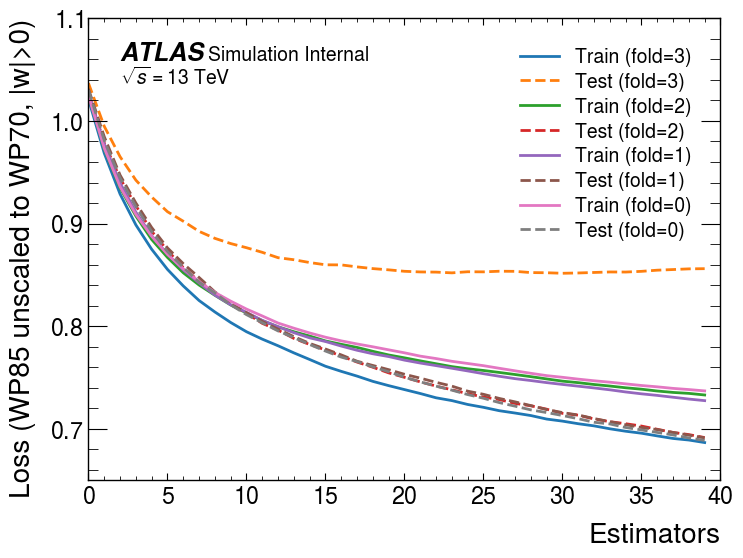

In [135]:
nfolds = 4
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds-1, -1, -1):  # Reverse order    
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss (WP85 unscaled to WP70, |w|>0)')
plt.show()

In [136]:
nfolds = 5
models = []
scores_train, scores_test = [], []
testloss = {fold: [] for fold in range(nfolds)}
trainloss = {fold: [] for fold in range(nfolds)}

# Store dataset splits for later use
splits = []

for fold in range(nfolds):
    print(f"\nFold: {fold}")

    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Store splits
    splits.append(((X_sig_train, w_sig_train, X_bkg_train_prompts, w_bkg_train_prompts, X_bkg_train_fakes, w_bkg_train_fakes),
                   (X_sig_test, w_sig_test, X_bkg_test_prompts, w_bkg_test_prompts, X_bkg_test_fakes, w_bkg_test_fakes)))

# Train on first 4 folds only
#for fold in range(nfolds - 1):
    print(f"\nTraining on Fold {fold}")

    (X_sig_train, w_sig_train, X_bkg_train_prompts, w_bkg_train_prompts, X_bkg_train_fakes, w_bkg_train_fakes), \
    (X_sig_test, w_sig_test, X_bkg_test_prompts, w_bkg_test_prompts, X_bkg_test_fakes, w_bkg_test_fakes) = splits[fold]

    y_train = np.concatenate([np.zeros_like(w_sig_train), np.ones_like(w_bkg_train_prompts), 2 * np.ones_like(w_bkg_train_fakes)])
    X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
    w_train = np.concatenate([w_sig_train, w_bkg_train_prompts, w_bkg_train_fakes])

    y_test = np.concatenate([np.zeros_like(w_sig_test), np.ones_like(w_bkg_test_prompts), 2 * np.ones_like(w_bkg_test_fakes)])
    X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
    w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

    print(f"\nFold {fold} Data Overview:")
    print(f"Signal: {len(X_sig_train)} train, {len(X_sig_test)} test")
    print(f"Prompt Background: {len(X_bkg_train_prompts)} train, {len(X_bkg_test_prompts)} test")
    print(f"Fake Background: {len(X_bkg_train_fakes)} train, {len(X_bkg_test_fakes)} test")

    # Train XGBClassifier
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))

    models.append(model)
    scores_train.append(model.score(X_train, y_train, sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test, y_test, sample_weight=np.abs(w_test)))

    print(f"Train scores (Fold {fold}):", scores_train[-1])
    print(f"Test scores (Fold {fold}):", scores_test[-1])



Fold: 0

Training on Fold 0

Fold 0 Data Overview:
Signal: 287276 train, 71611 test
Prompt Background: 2240 train, 564 test
Fake Background: 2468 train, 583 test
Train scores (Fold 0): 0.704185070088537
Test scores (Fold 0): 0.6001130891227976

Fold: 1

Training on Fold 1

Fold 1 Data Overview:
Signal: 287039 train, 71848 test
Prompt Background: 2252 train, 552 test
Fake Background: 2452 train, 599 test
Train scores (Fold 1): 0.7062890916894613
Test scores (Fold 1): 0.6219541042850026

Fold: 2

Training on Fold 2

Fold 2 Data Overview:
Signal: 287200 train, 71687 test
Prompt Background: 2233 train, 571 test
Fake Background: 2437 train, 614 test
Train scores (Fold 2): 0.7078991990917717
Test scores (Fold 2): 0.594243199749402

Fold: 3

Training on Fold 3

Fold 3 Data Overview:
Signal: 286827 train, 72060 test
Prompt Background: 2249 train, 555 test
Fake Background: 2444 train, 607 test
Train scores (Fold 3): 0.7033413264259392
Test scores (Fold 3): 0.6364283566998838

Fold: 4

Training

In [108]:
print(models[1].get_params())
print(models[3].get_params())


{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 40, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': None, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': 2}
{'objective': 'multi:softprob', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylev

In [129]:
print(f"Number of boosters: {len(models[3].get_booster().get_dump())}")


Number of boosters: 120


In [137]:
# Testing loss curve - 06.02.2025

###############################

nfolds = 5
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(len(X_train))
print(len(X_test))


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        #print(len(ypred_train),len(ypred_test))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)
    print(f"Fold {fold} >")
    print(trainloss[fold])
    print(testloss[fold])


291851
72891
Fold 0 >
[1.0268099061806668, 0.9769579434097427, 0.9408708871200784, 0.9135487104543761, 0.8905201902131682, 0.8727217105786631, 0.8580595986047332, 0.8467519766880224, 0.8364735567832067, 0.8267098837676486, 0.8190087019509411, 0.8111793717812513, 0.8043732435454131, 0.7986018380348612, 0.794638108501084, 0.7906393212535429, 0.7858004665094194, 0.7823700828558028, 0.7787311410589637, 0.7753742707640896, 0.7721034637864015, 0.7697140600532738, 0.7665843669657406, 0.7638667979050237, 0.7613600862568344, 0.7587146249900746, 0.7566402323893632, 0.7547266641737758, 0.7530803105268107, 0.7511835758942031, 0.7492543777360007, 0.747613602957905, 0.7459989764667905, 0.7440449161592859, 0.742172650074594, 0.740516796853362, 0.7393396175096766, 0.737874980303936, 0.736454289040265, 0.73524360095632]
[1.021093209997092, 0.9685728000734745, 0.9295156008531879, 0.8984083759512137, 0.8749565198872673, 0.8554999583683182, 0.8395487095164631, 0.8270098089999379, 0.8147941859338114, 0.804

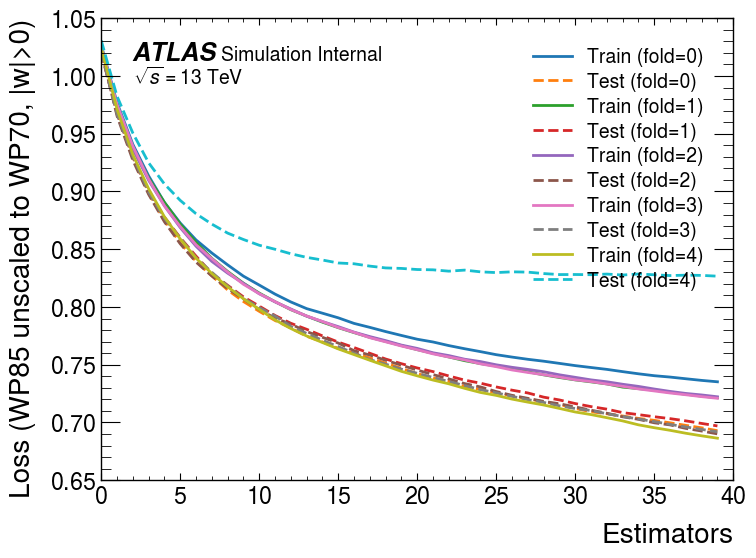

In [138]:
nfolds = 5
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss (WP85 unscaled to WP70, |w|>0)')
plt.show()

In [144]:

# Define number of folds and estimators
nfolds = 5
n_estimators = 40  # Adjust as needed

# Placeholder lists for models, scores, and losses
models = []
scores_train, scores_test = [], []
trainloss, testloss = {fold: [] for fold in range(nfolds)}, {fold: [] for fold in range(nfolds)}

# Placeholder to store dataset splits
splits = []

# Split dataset into 5 folds
for fold in range(nfolds):
    print(f"\nSplitting Fold {fold}")

    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Store split data for later access
    splits.append(((X_sig_train, w_sig_train, X_bkg_train_prompts, w_bkg_train_prompts, X_bkg_train_fakes, w_bkg_train_fakes),
                   (X_sig_test, w_sig_test, X_bkg_test_prompts, w_bkg_test_prompts, X_bkg_test_fakes, w_bkg_test_fakes)))

# Train on first 4 folds, leaving out fold 5
print("\nTraining on first 4 folds, leaving out fold 5...")
folds_to_train = list(range(nfolds - 1))
fold_to_test = nfolds - 1  # Fold 5

# Collect training data
X_train = np.concatenate([splits[f][0][0] for f in folds_to_train])
w_train = np.concatenate([splits[f][0][1] for f in folds_to_train] + 
                         [splits[f][0][3] for f in folds_to_train] + 
                         [splits[f][0][5] for f in folds_to_train])

y_train = np.concatenate([
    np.zeros(len(splits[f][0][1])) for f in folds_to_train
] + [
    np.ones(len(splits[f][0][3])) for f in folds_to_train
] + [
    2 * np.ones(len(splits[f][0][5])) for f in folds_to_train
]).astype(int)

# Extract test set (Fold 5)
(X_sig_test, w_sig_test, X_bkg_test_prompts, w_bkg_test_prompts, X_bkg_test_fakes, w_bkg_test_fakes) = splits[fold_to_test][1]

y_test = np.concatenate([
    np.zeros(len(w_sig_test)),
    np.ones(len(w_bkg_test_prompts)),
    2 * np.ones(len(w_bkg_test_fakes))
]).astype(int)

print(len(X_train), len(y_train))
X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

# Train model
model_4folds = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
model_4folds.fit(X_train, y_train, sample_weight=np.abs(w_train))

# Compute loss curve
trainloss_4folds, testloss_4folds = [], []

for i in range(n_estimators):
    ypred_train = model_4folds.predict_proba(X_train, iteration_range=(0, i+1))
    ypred_test = model_4folds.predict_proba(X_test, iteration_range=(0, i+1))

    loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
    loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))

    trainloss_4folds.append(loss_train)
    testloss_4folds.append(loss_test)

# Plot loss curve for 4-fold model
plt.figure(figsize=(8, 6))
plt.plot(range(n_estimators), trainloss_4folds, label='Train (4 Folds)')
plt.plot(range(n_estimators), testloss_4folds, label='Test (Fold 5)', linestyle='--')
plt.xlabel("Number of Estimators")
plt.ylabel("Log Loss")
plt.legend()
plt.title("Loss Curve (Training on 4 Folds, Testing on Fold 5)")
plt.show()


# Train on all 5 folds and plot
print("\nTraining on all 5 folds...")

# Collect training data from all folds
X_train_all = np.concatenate([splits[f][0][0] for f in range(nfolds)])
w_train_all = np.concatenate([splits[f][0][1] for f in range(nfolds)] + 
                             [splits[f][0][3] for f in range(nfolds)] + 
                             [splits[f][0][5] for f in range(nfolds)])

y_train_all = np.concatenate([
    np.zeros(len(splits[f][0][1])) for f in range(nfolds)
] + [
    np.ones(len(splits[f][0][3])) for f in range(nfolds)
] + [
    2 * np.ones(len(splits[f][0][5])) for f in range(nfolds)
]).astype(int)

# Train model on all folds
model_5folds = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
model_5folds.fit(X_train_all, y_train_all, sample_weight=np.abs(w_train_all))

# Compute loss curve for 5-fold training
trainloss_5folds = []

for i in range(n_estimators):
    ypred_train_all = model_5folds.predict_proba(X_train_all, iteration_range=(0, i+1))
    loss_train_all = metrics.log_loss(y_train_all, ypred_train_all, sample_weight=np.abs(w_train_all))
    trainloss_5folds.append(loss_train_all)

# Plot loss curve for 5-fold training
plt.figure(figsize=(8, 6))
plt.plot(range(n_estimators), trainloss_5folds, label='Train (5 Folds)')
plt.xlabel("Number of Estimators")
plt.ylabel("Log Loss")
plt.legend()
plt.title("Loss Curve (Training on All 5 Folds)")
plt.show()



Splitting Fold 0

Splitting Fold 1

Splitting Fold 2

Splitting Fold 3

Splitting Fold 4

Training on first 4 folds, leaving out fold 5...
1148342 1167117


XGBoostError: [13:21:23] /build/jenkins/workspace/lcg_release_pipeline/build/pyexternals/xgboost-2.0.2/src/xgboost/2.0.2/src/data/data.cc:501: Check failed: this->labels.Size() % this->num_row_ == 0 (18775 vs. 0) : Incorrect size for labels.
Stack trace:
  [bt] (0) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(dmlc::LogMessageFatal::~LogMessageFatal()+0x71) [0x7fc1d49231c1]
  [bt] (1) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfoFromHost(xgboost::Context const&, xgboost::StringView, xgboost::Json)+0xd3f) [0x7fc1d4b18eff]
  [bt] (2) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfo(xgboost::Context const&, xgboost::StringView, xgboost::StringView)+0x1da) [0x7fc1d4b1a96a]
  [bt] (3) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x

In [142]:
# Train on folds 0-3, leaving out fold 5
folds_to_train = list(range(nfolds - 1))
X_train = np.concatenate([splits[f][0][0] for f in folds_to_train])  # X_train from folds 0-3
w_train = np.concatenate([splits[f][0][1] for f in folds_to_train] + 
                         [splits[f][0][3] for f in folds_to_train] + 
                         [splits[f][0][5] for f in folds_to_train])

# Construct y_train properly
y_train_signal = np.zeros_like(splits[0][0][1])  # Class 0 (Signal)
y_train_prompt = np.ones_like(splits[0][0][3])   # Class 1 (Prompt Background)
y_train_fake = 2 * np.ones_like(splits[0][0][5])  # Class 2 (Fake Background)

# Concatenate labels for all folds 0-3
y_train = np.concatenate([
    np.concatenate([np.zeros_like(splits[f][0][1]) for f in folds_to_train]),  # Signal
    np.concatenate([np.ones_like(splits[f][0][3]) for f in folds_to_train]),   # Prompt Background
    np.concatenate([2 * np.ones_like(splits[f][0][5]) for f in folds_to_train])  # Fake Background
]).astype(int)  # Ensure labels are integers

# Extract test set for fold 5
(X_sig_test, w_sig_test, X_bkg_test_prompts, w_bkg_test_prompts, X_bkg_test_fakes, w_bkg_test_fakes) = splits[fold_to_test][1]
y_test = np.concatenate([
    np.zeros_like(w_sig_test),
    np.ones_like(w_bkg_test_prompts),
    2 * np.ones_like(w_bkg_test_fakes)
]).astype(int)  # Ensure integer labels

X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

# Debug print to check class labels
print(f"Unique train labels: {np.unique(y_train)}")
print(f"Unique test labels: {np.unique(y_test)}")

# Train the model
print("\nTraining model for Fold 5...")
model_5th = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
model_5th.fit(X_train, y_train, sample_weight=np.abs(w_train))


Unique train labels: [0 1 2]
Unique test labels: [0 1 2]

Training model for Fold 5...


XGBoostError: [13:12:33] /build/jenkins/workspace/lcg_release_pipeline/build/pyexternals/xgboost-2.0.2/src/xgboost/2.0.2/src/data/data.cc:501: Check failed: this->labels.Size() % this->num_row_ == 0 (18775 vs. 0) : Incorrect size for labels.
Stack trace:
  [bt] (0) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(dmlc::LogMessageFatal::~LogMessageFatal()+0x71) [0x7fc1d49231c1]
  [bt] (1) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfoFromHost(xgboost::Context const&, xgboost::StringView, xgboost::Json)+0xd3f) [0x7fc1d4b18eff]
  [bt] (2) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfo(xgboost::Context const&, xgboost::StringView, xgboost::StringView)+0x1da) [0x7fc1d4b1a96a]
  [bt] (3) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x

In [118]:
nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}




for fold in range(nfolds):
    print(f"\n===== Processing Fold {fold} =====")
    
    for i in range(1, n_estimators + 1):  # Iterate through trees
        print(f"  Processing {i}/{n_estimators} estimators in fold {fold}...")

        # Predict probabilities using trees up to iteration i
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i))

        # Debug: Check shape of predictions
        print(f"    Shape of ypred_train: {ypred_train.shape}, ypred_test: {ypred_test.shape}")

        # Normalize probabilities for multi-class classification
        ypred_train /= ypred_train.sum(axis=1, keepdims=True)
        ypred_test /= ypred_test.sum(axis=1, keepdims=True)

        # Debug: Check if probabilities sum to 1
        print(f"    Sum check (train): {ypred_train.sum(axis=1)[:5]}")
        print(f"    Sum check (test): {ypred_test.sum(axis=1)[:5]}")

        # Compute the log loss (ensuring weights are handled correctly)
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))

        # Debug: Check computed loss values
        print(f"    Loss (train): {loss_train:.6f}, Loss (test): {loss_test:.6f}")

        # Store or plot loss values
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)



    # Check if any class is missing in train or test
    unique_train_classes = np.unique(y_train)
    unique_test_classes = np.unique(y_test)
    print(f"    Unique classes in train: {unique_train_classes}")
    print(f"    Unique classes in test: {unique_test_classes}")

#    if len(unique_train_classes) < 3 or len(unique_test_classes) < 3:
#        print("  ⚠ WARNING: Some classes might be missing in this fold!")

print("\n===== Training Completed =====")



===== Processing Fold 0 =====
  Processing 1/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 1.024256, Loss (test): 1.030030
  Processing 2/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        0.9999999 1.        1.        1.       ]
    Loss (train): 0.973220, Loss (test): 0.981055
  Processing 3/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.935837, Loss (test): 0.944567
  Processing 4/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.908832, Loss (test): 0.916567
  

    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.745507, Loss (test): 0.704836
  Processing 35/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.743883, Loss (test): 0.701385
  Processing 36/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        1.        1.        1.0000001 1.       ]
    Loss (train): 0.742298, Loss (test): 0.699006
  Processing 37/40 estimators in fold 0...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.740997, Loss (test): 0.696565
  Processing 38/40 estimators in fold 0...
    Shape of ypred_train: (27

    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        1.        1.        1.0000001 1.       ]
    Loss (train): 0.751284, Loss (test): 0.729688
  Processing 28/40 estimators in fold 1...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.748953, Loss (test): 0.726345
  Processing 29/40 estimators in fold 1...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        1.        1.        1.0000001 1.       ]
    Loss (train): 0.747112, Loss (test): 0.722715
  Processing 30/40 estimators in fold 1...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.745097, Loss (test): 0.718885
  Processing 31/40 estimators in fold

    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.772031, Loss (test): 0.754586
  Processing 21/40 estimators in fold 2...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        1.        1.        0.9999999 1.       ]
    Loss (train): 0.769236, Loss (test): 0.750272
  Processing 22/40 estimators in fold 2...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [0.99999994 1.         1.         1.         1.        ]
    Loss (train): 0.766290, Loss (test): 0.745833
  Processing 23/40 estimators in fold 2...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.763483, Loss (test): 0.741747
  Processing 24/40 estimators in

    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [0.99999994 1.         1.         1.         1.        ]
    Loss (train): 0.787445, Loss (test): 0.872003
  Processing 13/40 estimators in fold 3...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [0.99999994 1.         1.         1.         1.        ]
    Loss (train): 0.780987, Loss (test): 0.866769
  Processing 14/40 estimators in fold 3...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [1. 1. 1. 1. 1.]
    Sum check (test): [1.        1.        1.        1.        1.0000001]
    Loss (train): 0.774067, Loss (test): 0.864795
  Processing 15/40 estimators in fold 3...
    Shape of ypred_train: (273653, 3), ypred_test: (91089, 3)
    Sum check (train): [0.99999994 1.         1.         1.         1.        ]
    Sum check (test): [1. 1. 1. 1. 1.]
    Loss (train): 0.767615, Loss (test): 0.862058
  Processing 1


Training model for Fold 5...


XGBoostError: [13:10:32] /build/jenkins/workspace/lcg_release_pipeline/build/pyexternals/xgboost-2.0.2/src/xgboost/2.0.2/src/data/data.cc:501: Check failed: this->labels.Size() % this->num_row_ == 0 (18775 vs. 0) : Incorrect size for labels.
Stack trace:
  [bt] (0) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(dmlc::LogMessageFatal::~LogMessageFatal()+0x71) [0x7fc1d49231c1]
  [bt] (1) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfoFromHost(xgboost::Context const&, xgboost::StringView, xgboost::Json)+0xd3f) [0x7fc1d4b18eff]
  [bt] (2) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/lib/libxgboost.so(xgboost::MetaInfo::SetInfo(xgboost::Context const&, xgboost::StringView, xgboost::StringView)+0x1da) [0x7fc1d4b1a96a]
  [bt] (3) /cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x

In [120]:
273653+91089

364742

In [123]:

nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(len(X_train))
print(len(X_test))



for fold in range(nfolds):
    # Get the actual number of trees after training (important!)
    n_actual_estimators = models[fold].best_iteration if hasattr(models[fold], 'best_iteration') else models[fold].n_estimators
    print(f'Actual estimators: {n_actual_estimators}')
    for i in range(n_actual_estimators):  # Iterate up to the *actual* number of trees
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))

        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))

        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)
    print(f"Fold {fold} >")
    print(trainloss[fold])
    print(testloss[fold])






273653
91089
Actual estimators: 40
Fold 0 >
[1.0242561150500809, 0.9732201353768439, 0.9358366575311073, 0.9088319707075255, 0.8876119393131323, 0.8699449337430697, 0.8560455920741624, 0.8434624000781618, 0.8329770014805089, 0.8244673590594155, 0.8167413574950119, 0.810014429049472, 0.8031166349344304, 0.7981012133774233, 0.793463561020122, 0.7893244402070785, 0.785772112398235, 0.7827534152724266, 0.7799882778878922, 0.7770366834128598, 0.7741247862308303, 0.7708925805416185, 0.7685347680576896, 0.7658546633731563, 0.7637389371299689, 0.7615950799679514, 0.759060255797267, 0.7565942696708414, 0.754164571255021, 0.7519098150644944, 0.7502771891971507, 0.7484940936966259, 0.7469041546273009, 0.7455071703889385, 0.7438830193771205, 0.7422980268751742, 0.7409971795719194, 0.7394775933951871, 0.73833808529541, 0.7370337402912976]
[1.0300296264516984, 0.9810547202310786, 0.944566742541702, 0.9165669058592438, 0.8922433981251281, 0.8728308783258546, 0.8572766495205054, 0.8429839318314168, 0.

In [42]:



nfolds = 4
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}

print(n_boosters)


for fold in range(nfolds):
    #n_boosters = len(models[fold].get_booster().get_dump()) # This ensures we are within the actual range
    for i in range(n_estimators):   # change these numbers accordingly
        # print("Value of tree:",i)
        # Predict probabilities for a subset of trees from 1 to i+1
        ypred_train = models[fold].predict_proba(X_train, iteration_range=(0, i+1))
        ypred_test = models[fold].predict_proba(X_test, iteration_range=(0, i+1))
        
        # Compute the log loss with the true labels and predicted probabilities
        loss_train = metrics.log_loss(y_train, ypred_train, sample_weight=np.abs(w_train))
        loss_test = metrics.log_loss(y_test, ypred_test, sample_weight=np.abs(w_test))
        
        # Append the loss values to respective lists
        trainloss[fold].append(loss_train)
        testloss[fold].append(loss_test)

99


IndexError: list index out of range

In [32]:
for i, model in enumerate(models):
    # Assuming model[0] has the feature importance scores
    feature_importances = models[i].feature_importances_

    # Create a list of tuples with feature name and importance
    feature_imp_list = zip(feature_cols, feature_importances)
    print(feature_imp_list) 
    # Sort the list based on importance in ascending order (key=lambda x: x[1])
    sorted_features = sorted(feature_imp_list, key=lambda x: x[1])
    print(f'for model: {i}')
    # Print the sorted features
    for feature, importance in sorted_features:
        print(f"Feature Name: {feature}, Importance: {importance}")
        
    print(F"No. of features: {len(sorted_features)}")

for model: 0
Feature Name: ph_pt[:,0], Importance: 0.013898824341595173
Feature Name: ph_eta[:,0], Importance: 0.014995048753917217
Feature Name: met_met, Importance: 0.01866046153008938
Feature Name: jet_pt[:,1], Importance: 0.018772786483168602
Feature Name: ph_mlph_closest[:,0], Importance: 0.020450735464692116
Feature Name: dr_ph, Importance: 0.02079199254512787
Feature Name: ph_mphb85_closest[:,0], Importance: 0.023372620344161987
Feature Name: ph_eta[:,1], Importance: 0.023540474474430084
Feature Name: ph_mphb85_closest[:,1], Importance: 0.02468569576740265
Feature Name: m_AllObjects, Importance: 0.02474883757531643
Feature Name: dr_lep_ph1, Importance: 0.028331276029348373
Feature Name: ph_pt[:,1], Importance: 0.028668113052845
Feature Name: diph_M, Importance: 0.032977767288684845
Feature Name: jet_pt[:,0], Importance: 0.03538825362920761
Feature Name: dr_lep_ph0, Importance: 0.03565322235226631
Feature Name: event_nbjets85, Importance: 0.04803058132529259
Feature Name: ph_mlph

In [252]:
mplhep.style.use('ATLAS')
nbins = 10

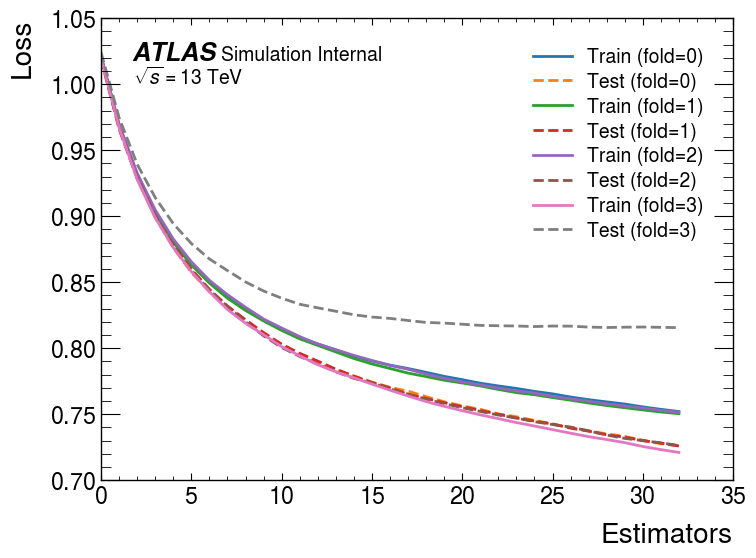

In [253]:
nbins = 10
nfolds = 4
n_estimators = 33
# Plotting the results
fig, ax = plt.subplots()
for fold in range(nfolds):
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend()
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss')
plt.show()

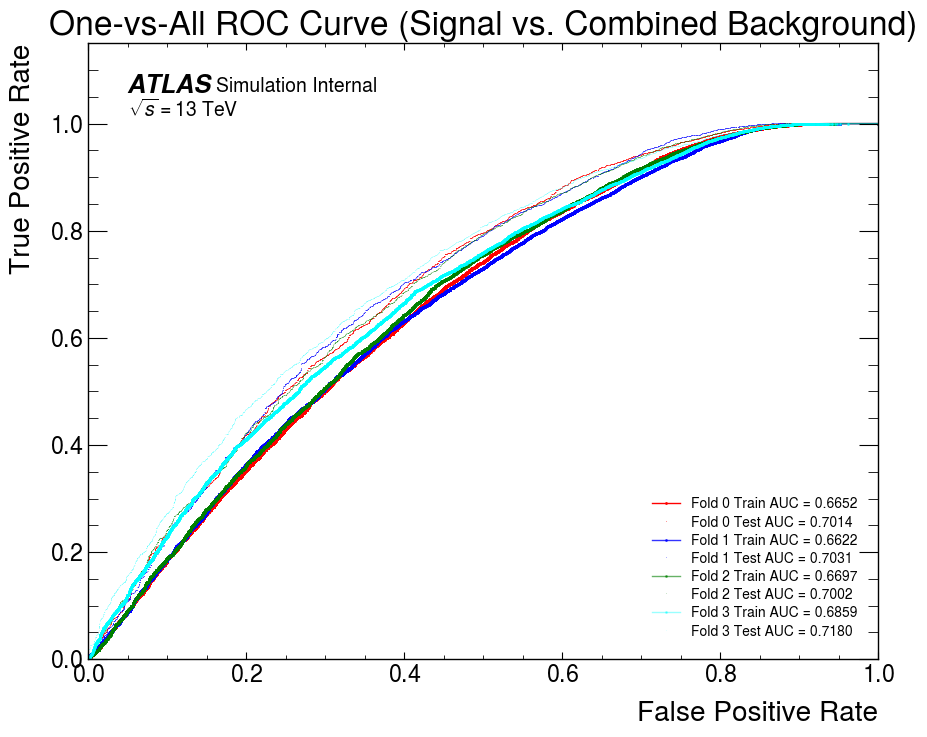

In [167]:

# Define number of folds
nfolds = 4

# Define colors for folds (ensuring strong contrast)
colors = ['red', 'blue', 'green', 'cyan']

# Set figure size
plt.figure(figsize=(10, 8))

# Loop over folds
for fold in range(nfolds):
    # Extract training data
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Predict probabilities for training set
    results_sig_train = models[fold].predict_proba(X_sig_train)[:, 0]  # Signal class (0)
    results_bkg_prompts_train = models[fold].predict_proba(X_bkg_train_prompts)[:, 1]  # Background class 1
    results_bkg_fakes_train = models[fold].predict_proba(X_bkg_train_fakes)[:, 2]  # Background class 2

    # Predict probabilities for test set
    results_sig_test = models[fold].predict_proba(X_sig_test)[:, 0]  # Signal class (0)
    results_bkg_prompts_test = models[fold].predict_proba(X_bkg_test_prompts)[:, 1]  # Background class 1
    results_bkg_fakes_test = models[fold].predict_proba(X_bkg_test_fakes)[:, 2]  # Background class 2

    # Combine background categories into a single class
    results_bkg_train = np.concatenate([results_bkg_prompts_train, results_bkg_fakes_train])
    results_bkg_test = np.concatenate([results_bkg_prompts_test, results_bkg_fakes_test])

    # Create labels: 1 for signal, 0 for background
    y_train = np.concatenate([np.ones_like(results_sig_train), np.zeros_like(results_bkg_train)])
    y_test = np.concatenate([np.ones_like(results_sig_test), np.zeros_like(results_bkg_test)])

    # Combine predictions
    scores_train = np.concatenate([results_sig_train, results_bkg_train])
    scores_test = np.concatenate([results_sig_test, results_bkg_test])

    # Calculate ROC curve and AUC for training
    fpr_train, tpr_train, _ = metrics.roc_curve(y_train, scores_train, pos_label=1)
    auc_train = metrics.roc_auc_score(y_train, scores_train)

    # Calculate ROC curve and AUC for testing
    fpr_test, tpr_test, _ = metrics.roc_curve(y_test, scores_test, pos_label=1)
    auc_test = metrics.roc_auc_score(y_test, scores_test)

    # Set opacity (later folds get lower opacity)
    alpha_train = 1.0 - (0.2 * fold)  # Train curves: more visible
    alpha_test = 0.4 - (0.1 * fold)  # Test curves: slightly more transparent

    # Markers and linestyles
    marker_train = 'o'  # Signal: circles
    marker_test = ','  # Background: crosses
    linestyle_train = '-'  # Solid line for training
    linestyle_test = ''  # Dashed line for testing

    # Plot train AUC curve
    plt.plot(
        fpr_train, tpr_train,
        label=f'Fold {fold} Train AUC = {auc_train:.4f}',
        color=colors[fold], alpha=alpha_train,
        linewidth=1.0, linestyle=linestyle_train, marker=marker_train, markersize=1
    )

    # Plot test AUC curve
    plt.plot(
        fpr_test, tpr_test,
        label=f'Fold {fold} Test AUC = {auc_test:.4f}',
        color=colors[fold], alpha=alpha_test,
        linewidth=1.0, linestyle=linestyle_test, marker=marker_test, markersize=50
    )

# Formatting the plot
plt.legend(loc='lower right', fontsize=10)
plt.xlim(0, 1)
plt.ylim(0, 1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('One-vs-All ROC Curve (Signal vs. Combined Background)')
mplhep.atlas.label('Internal', data=False)
plt.show()



============================== Fold 0 ==============================

 **Class Distribution Check**
Training: Class 0: 269250, Class 1: 2100, Class 2: 2303
Testing: Class 0: 89637, Class 1: 704, Class 2: 748

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37263486e+05  8.96759329e+04  7.65304938e+04 -2.51958970e-03
  5.82590581e-04  9.73013180e+04  4.10860721e+04  1.47323520e+05
  9.10897508e+04  1.17727215e+05  1.78265541e+00  2.06248696e+00
  1.89104913e+00  7.24757266e-01  7.57528695e-01  1.39877323e+05
  9.00406668e+04  8.52118471e+05  4.66817466e+00  2.11329905e+00]
Feature Mean (Test): [ 1.37330737e+05  8.97379977e+04  7.63389502e+04 -2.61802791e-03
 -2.08240044e-03  9.69103115e+04  4.10017921e+04  1.46878508e+05
  9.10349755e+04  1.17366397e+05  1.78181778e+00  2.06112904e+00
  1.89560201e+00  7.25345541e-01  7.56040795e-01  1.39784937e+05
  8.98858984e+04  8.50327741e+05  4.66611775e+00  2.11592266e+00]
Feature Std (Train): [7.47485247e+04 4.58316182e+04 5.8067

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.98772	validation_1-mlogloss:0.98814
[1]	validation_0-mlogloss:0.91297	validation_1-mlogloss:0.91374
[2]	validation_0-mlogloss:0.86388	validation_1-mlogloss:0.86493
[3]	validation_0-mlogloss:0.82199	validation_1-mlogloss:0.82335
[4]	validation_0-mlogloss:0.79191	validation_1-mlogloss:0.79355
[5]	validation_0-mlogloss:0.76891	validation_1-mlogloss:0.77064
[6]	validation_0-mlogloss:0.74882	validation_1-mlogloss:0.75068
[7]	validation_0-mlogloss:0.73422	validation_1-mlogloss:0.73626
[8]	validation_0-mlogloss:0.72093	validation_1-mlogloss:0.72312
[9]	validation_0-mlogloss:0.71261	validation_1-mlogloss:0.71489
[10]	validation_0-mlogloss:0.70198	validation_1-mlogloss:0.70430
[11]	validation_0-mlogloss:0.69376	validation_1-mlogloss:0.69618
[12]	validation_0-mlogloss:0.68752	validation_1-mlogloss:0.69009
[13]	validation_0-mlogloss:0.68117	validation_1-mlogloss:0.68377
[14]	validation_0-mlogloss:0.67497	validation_1-mlogloss:0.67762
[15]	validation_0-mlogloss:0.67027	

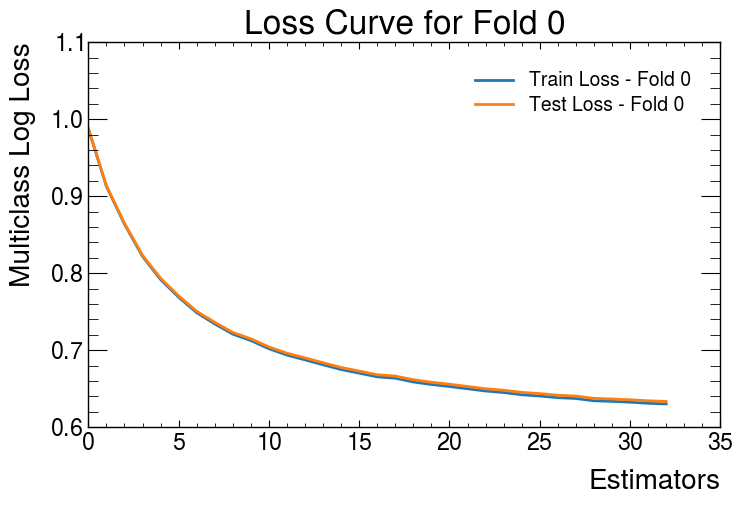


============================== Fold 1 ==============================

 **Class Distribution Check**
Training: Class 0: 269313, Class 1: 2106, Class 2: 2321
Testing: Class 0: 89574, Class 1: 698, Class 2: 730

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37279483e+05  8.96293451e+04  7.65302592e+04 -3.40852536e-03
  2.40326250e-04  9.72024223e+04  4.10696413e+04  1.47275996e+05
  9.11596644e+04  1.17724346e+05  1.78304596e+00  2.06274359e+00
  1.89437072e+00  7.23127785e-01  7.57967414e-01  1.39974675e+05
  8.99514455e+04  8.51553171e+05  4.66710747e+00  2.11433463e+00]
Feature Mean (Test): [ 1.37282681e+05  8.98781962e+04  7.63394725e+04  5.58549068e-05
 -1.05539462e-03  9.72074224e+04  4.10511366e+04  1.47021037e+05
  9.08246184e+04  1.17374681e+05  1.78064218e+00  2.06035577e+00
  1.88561480e+00  7.30247687e-01  7.54719676e-01  1.39492009e+05
  9.01541340e+04  8.52026486e+05  4.66932595e+00  2.11281008e+00]
Feature Std (Train): [7.46821720e+04 4.58742258e+04 5.8044

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.99330	validation_1-mlogloss:0.99337
[1]	validation_0-mlogloss:0.91838	validation_1-mlogloss:0.91846
[2]	validation_0-mlogloss:0.86510	validation_1-mlogloss:0.86492
[3]	validation_0-mlogloss:0.82320	validation_1-mlogloss:0.82309
[4]	validation_0-mlogloss:0.79611	validation_1-mlogloss:0.79573
[5]	validation_0-mlogloss:0.77093	validation_1-mlogloss:0.77055
[6]	validation_0-mlogloss:0.75191	validation_1-mlogloss:0.75154
[7]	validation_0-mlogloss:0.73605	validation_1-mlogloss:0.73557
[8]	validation_0-mlogloss:0.72092	validation_1-mlogloss:0.72043
[9]	validation_0-mlogloss:0.71189	validation_1-mlogloss:0.71149
[10]	validation_0-mlogloss:0.70337	validation_1-mlogloss:0.70299
[11]	validation_0-mlogloss:0.69555	validation_1-mlogloss:0.69519
[12]	validation_0-mlogloss:0.68868	validation_1-mlogloss:0.68821
[13]	validation_0-mlogloss:0.68292	validation_1-mlogloss:0.68259
[14]	validation_0-mlogloss:0.67640	validation_1-mlogloss:0.67615
[15]	validation_0-mlogloss:0.67369	

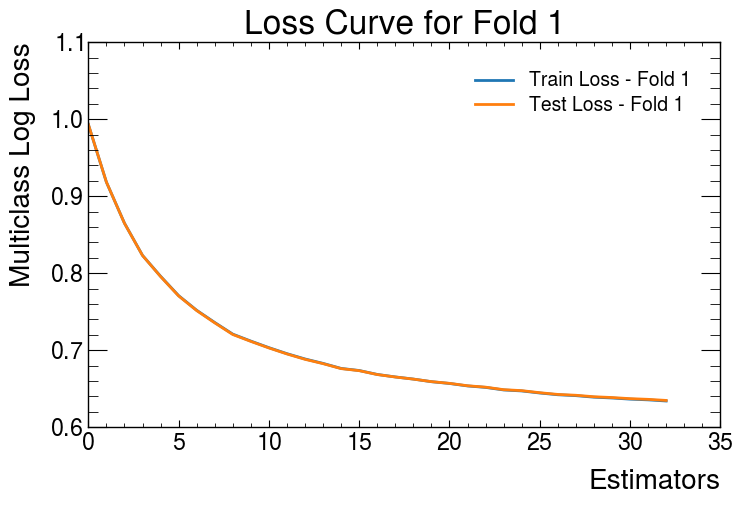


============================== Fold 2 ==============================

 **Class Distribution Check**
Training: Class 0: 269051, Class 1: 2127, Class 2: 2268
Testing: Class 0: 89836, Class 1: 677, Class 2: 783

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37294300e+05  8.97279653e+04  7.63377159e+04 -2.41233441e-03
 -7.27507550e-04  9.71328187e+04  4.10352176e+04  1.47318420e+05
  9.10532966e+04  1.17558581e+05  1.78236288e+00  2.06381382e+00
  1.89130845e+00  7.24797583e-01  7.56090782e-01  1.39865992e+05
  9.00444344e+04  8.51702923e+05  4.66782107e+00  2.11374868e+00]
Feature Mean (Test): [ 1.37238290e+05  8.95820116e+04  7.69167848e+04 -2.93905132e-03
  1.84759371e-03  9.74158801e+04  4.11543007e+04  1.46894790e+05
  9.11442859e+04  1.17872300e+05  1.78269585e+00  2.05715796e+00
  1.89481496e+00  7.25223449e-01  7.60350946e-01  1.39819086e+05
  8.98749647e+04  8.51576433e+05  4.66718148e+00  2.11457000e+00]
Feature Std (Train): [7.46978492e+04 4.60706744e+04 5.7875

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.99192	validation_1-mlogloss:0.99197
[1]	validation_0-mlogloss:0.91667	validation_1-mlogloss:0.91664
[2]	validation_0-mlogloss:0.86158	validation_1-mlogloss:0.86169
[3]	validation_0-mlogloss:0.82623	validation_1-mlogloss:0.82635
[4]	validation_0-mlogloss:0.79508	validation_1-mlogloss:0.79521
[5]	validation_0-mlogloss:0.77024	validation_1-mlogloss:0.77045
[6]	validation_0-mlogloss:0.75152	validation_1-mlogloss:0.75192
[7]	validation_0-mlogloss:0.73695	validation_1-mlogloss:0.73747
[8]	validation_0-mlogloss:0.72245	validation_1-mlogloss:0.72297
[9]	validation_0-mlogloss:0.71133	validation_1-mlogloss:0.71195
[10]	validation_0-mlogloss:0.70015	validation_1-mlogloss:0.70083
[11]	validation_0-mlogloss:0.69185	validation_1-mlogloss:0.69264
[12]	validation_0-mlogloss:0.68569	validation_1-mlogloss:0.68656
[13]	validation_0-mlogloss:0.67996	validation_1-mlogloss:0.68091
[14]	validation_0-mlogloss:0.67364	validation_1-mlogloss:0.67458
[15]	validation_0-mlogloss:0.67070	

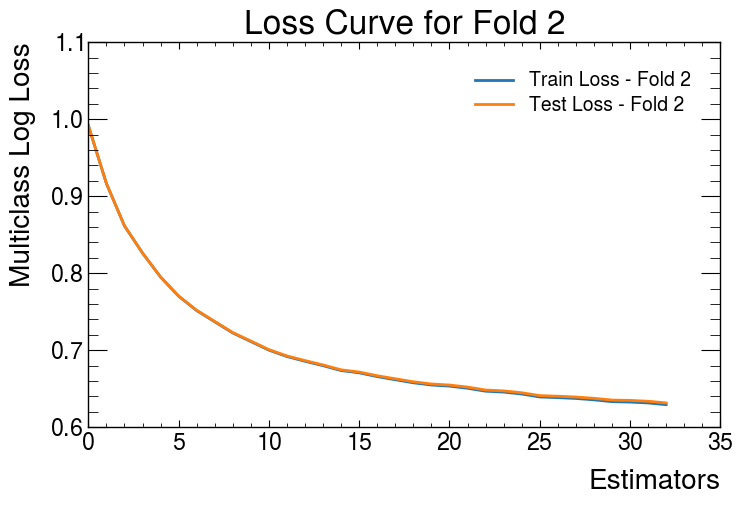


============================== Fold 3 ==============================

 **Class Distribution Check**
Training: Class 0: 269047, Class 1: 2079, Class 2: 2261
Testing: Class 0: 89840, Class 1: 725, Class 2: 790

 **Feature Statistics Across Folds**
Feature Mean (Train): [ 1.37283869e+05  8.97325747e+04  7.65320886e+04 -1.83517968e-03
 -4.28143545e-04  9.71780422e+04  4.10691467e+04  1.46931389e+05
  9.10014578e+04  1.17538098e+05  1.78171969e+00  2.05954552e+00
  1.89201475e+00  7.26936541e-01  7.57040386e-01  1.39698834e+05
  8.99715344e+04  8.51310193e+05  4.66754089e+00  2.11443487e+00]
Feature Mean (Test): [ 1.37269544e+05  8.95683118e+04  7.63347353e+04 -4.66589195e-03
  9.50060377e-04  9.72803625e+04  4.10526881e+04  1.48053286e+05
  9.12993588e+04  1.17933395e+05  1.78462044e+00  2.06993547e+00
  1.89269906e+00  7.18822177e-01  7.57506431e-01  1.40319349e+05
  9.00932331e+04  8.52751787e+05  4.66802036e+00  2.11251600e+00]
Feature Std (Train): [7.46937440e+04 4.61100462e+04 5.7931

/cvmfs/sft.cern.ch/lcg/views/LCG_105a_cuda/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/xgboost/sklearn.py:885: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(


[0]	validation_0-mlogloss:0.98947	validation_1-mlogloss:0.98952
[1]	validation_0-mlogloss:0.91310	validation_1-mlogloss:0.91311
[2]	validation_0-mlogloss:0.85734	validation_1-mlogloss:0.85735
[3]	validation_0-mlogloss:0.81655	validation_1-mlogloss:0.81675
[4]	validation_0-mlogloss:0.78607	validation_1-mlogloss:0.78627
[5]	validation_0-mlogloss:0.75924	validation_1-mlogloss:0.75937
[6]	validation_0-mlogloss:0.73921	validation_1-mlogloss:0.73935
[7]	validation_0-mlogloss:0.72278	validation_1-mlogloss:0.72300
[8]	validation_0-mlogloss:0.70984	validation_1-mlogloss:0.71000
[9]	validation_0-mlogloss:0.70035	validation_1-mlogloss:0.70052
[10]	validation_0-mlogloss:0.68787	validation_1-mlogloss:0.68806
[11]	validation_0-mlogloss:0.68078	validation_1-mlogloss:0.68102
[12]	validation_0-mlogloss:0.67368	validation_1-mlogloss:0.67391
[13]	validation_0-mlogloss:0.66611	validation_1-mlogloss:0.66636
[14]	validation_0-mlogloss:0.66266	validation_1-mlogloss:0.66286
[15]	validation_0-mlogloss:0.65721	

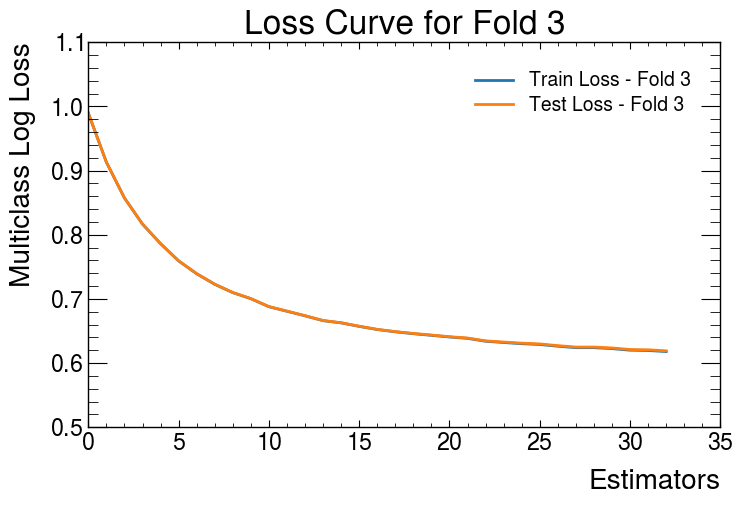

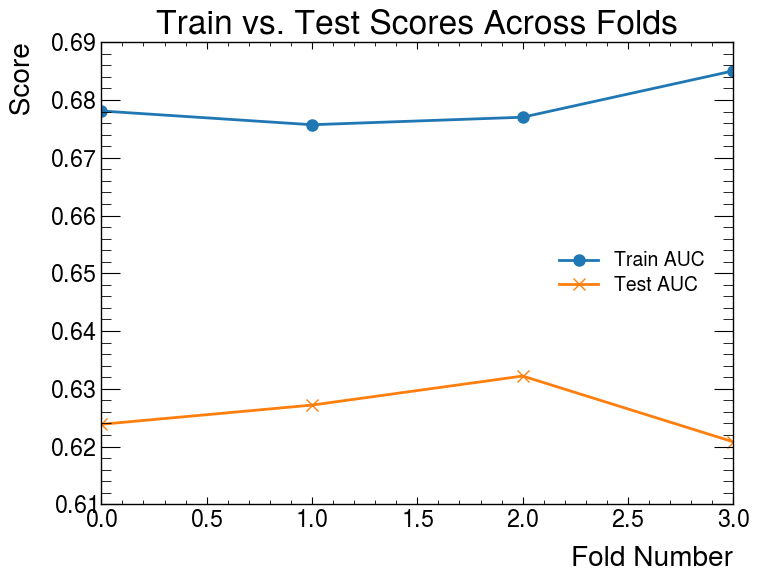

In [229]:
nfolds = 4

models_val = []
scores_train, scores_test = [], []
testloss = {fold: [] for fold in range(nfolds)}
trainloss = {fold: [] for fold in range(nfolds)}

for fold in range(nfolds):
    print(f"\n{'='*30} Fold {fold} {'='*30}")

    # Extract training and testing sets
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds != fold]
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber'] % nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber'] % nfolds == fold]

    X_bkg_train_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_prompts = df_bkg_prompt_85_reweighted[feature_cols][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_prompts = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber'] % nfolds == fold]

    X_bkg_train_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    w_bkg_train_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds != fold]
    X_bkg_test_fakes = df_bkg_fakes_85_reweighted[feature_cols][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]
    w_bkg_test_fakes = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber'] % nfolds == fold]

    # Combine classes
    y_train = np.concatenate([np.zeros_like(w_sig_train), np.ones_like(w_bkg_train_prompts), 2 * np.ones_like(w_bkg_train_fakes)])
    X_train = np.concatenate([X_sig_train, X_bkg_train_prompts, X_bkg_train_fakes])
    w_train = np.concatenate([w_sig_train, w_bkg_train_prompts, w_bkg_train_fakes])

    y_test = np.concatenate([np.zeros_like(w_sig_test), np.ones_like(w_bkg_test_prompts), 2 * np.ones_like(w_bkg_test_fakes)])
    X_test = np.concatenate([X_sig_test, X_bkg_test_prompts, X_bkg_test_fakes])
    w_test = np.concatenate([w_sig_test, w_bkg_test_prompts, w_bkg_test_fakes])

    ### **Validation Check 1: Dataset Integrity**
    print("\n **Class Distribution Check**")
    print(f"Training: Class 0: {np.sum(y_train == 0)}, Class 1: {np.sum(y_train == 1)}, Class 2: {np.sum(y_train == 2)}")
    print(f"Testing: Class 0: {np.sum(y_test == 0)}, Class 1: {np.sum(y_test == 1)}, Class 2: {np.sum(y_test == 2)}")


    ### **Validation Check 2: Feature Mean & Standard Deviation Comparison**
    print("\n **Feature Statistics Across Folds**")
    print(f"Feature Mean (Train): {X_train.mean(axis=0)}")
    print(f"Feature Mean (Test): {X_test.mean(axis=0)}")
    print(f"Feature Std (Train): {X_train.std(axis=0)}")
    print(f"Feature Std (Test): {X_test.std(axis=0)}")

    # Initialize XGBoost model
    model = XGBClassifier(
        tree_method="hist",
        verbosity=2,
        n_estimators=33,
        objective="multi:softmax",
        num_class=3
    )

    # Train the model
    eval_set = [(X_train, y_train), (X_test, y_test)]
    model.fit(
        X_train, y_train, sample_weight=np.abs(w_train),
        eval_set=eval_set, eval_metric="mlogloss", verbose=True     # using multi-class log loss function
    )

    models_val.append(model)
    scores_train.append(model.score(X_train, y_train, sample_weight=np.abs(w_train)))   # calculating accuracy
    scores_test.append(model.score(X_test, y_test, sample_weight=np.abs(w_test)))

    print(len(scores_train), len(scores_test))
    # Track loss
    results = model.evals_result()
    trainloss[fold] = results["validation_0"]["mlogloss"]
    testloss[fold] = results["validation_1"]["mlogloss"]

    ### **Validation Check 4: Loss Curve Plot**
    plt.figure(figsize=(8, 5))
    plt.plot(trainloss[fold], label=f"Train Loss - Fold {fold}")
    plt.plot(testloss[fold], label=f"Test Loss - Fold {fold}")
    plt.xlabel("Estimators")
    plt.ylabel("Multiclass Log Loss")
    plt.legend()
    plt.title(f"Loss Curve for Fold {fold}")
    plt.show()

# Plot AUC across folds
plt.figure(figsize=(8, 6))
plt.plot(range(nfolds), scores_train, label="Train AUC", marker="o")
plt.plot(range(nfolds), scores_test, label="Test AUC", marker="x")
plt.xlabel("Fold Number")
plt.ylabel(" Score")
plt.legend()
plt.title("Train vs. Test Scores Across Folds")
plt.show()


[0.42  0.203 0.377]


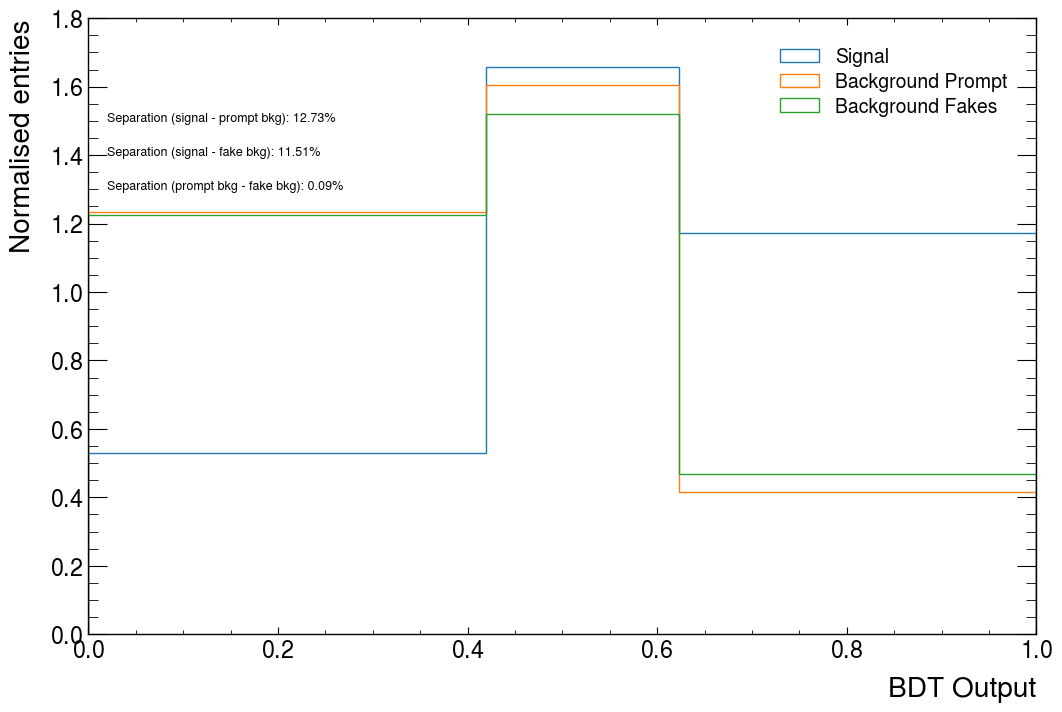

In [31]:
plt.figure(figsize=(12, 8))

# Define custom bin edges
custom_bins = [0., 0.42, 0.623, 1.] #[0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg_prompt, _, _ = plt.hist(results_bkg_prompts, weights=df_bkg_prompt_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Prompt')
bc_bkg_fake, _, _ = plt.hist(results_bkg_fakes, weights=df_bkg_fakes_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background Fakes')


# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
print(bin_widths)
separation_sig_bkgPrompt = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_prompt) ** 2) / (bc_sig + bc_bkg_prompt)) * bin_widths)
separation_sig_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg_fake) ** 2) / (bc_sig + bc_bkg_fake)) * bin_widths)
separation_bkgPrompt_bkgFake = 0.5 * np.sum(np.nan_to_num(((bc_bkg_prompt - bc_bkg_fake) ** 2) / (bc_bkg_prompt + bc_bkg_fake)) * bin_widths)

#separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.02, y=1.50, s=f'Separation (signal - prompt bkg): {separation_sig_bkgPrompt*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.40, s=f'Separation (signal - fake bkg): {separation_sig_bkgFake*100:.2f}%', fontsize = 9)
plt.text(x=0.02, y=1.30, s=f'Separation (prompt bkg - fake bkg): {separation_bkgPrompt_bkgFake*100:.2f}%', fontsize = 9)

#plt.savefig(f'separation_fittedbins_3class.pdf')
plt.legend()


In [32]:
results_bkg = np.concatenate([results_bkg_prompts,results_bkg_fakes])
df_bkg      = np.concatenate([df_bkg_prompt_85_reweighted,df_bkg_fakes_85_reweighted])

df_bkg_weight = np.concatenate([df_bkg_prompt_85_reweighted['weight'],df_bkg_fakes_85_reweighted['weight']])

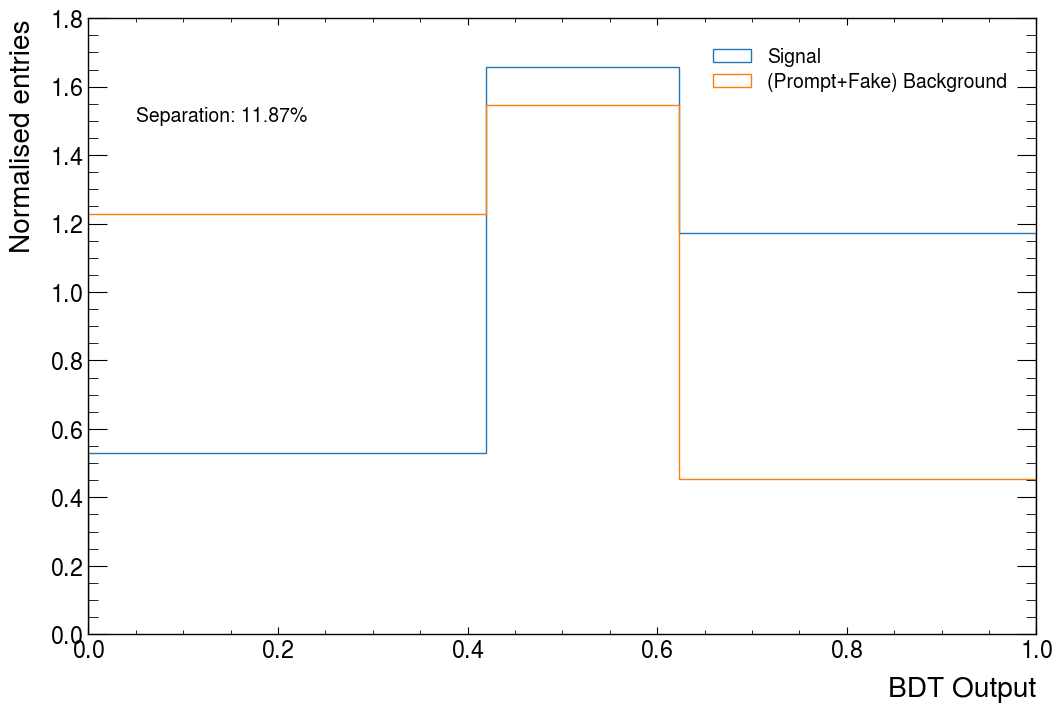

In [33]:
plt.figure(figsize=(12, 8))


# Define custom bin edges
custom_bins = [0., 0.42, 0.623, 1.] #[0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_weight, bins=custom_bins, histtype='step', density=True, label='(Prompt+Fake) Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.5, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins_3class_converged.pdf')
plt.legend()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

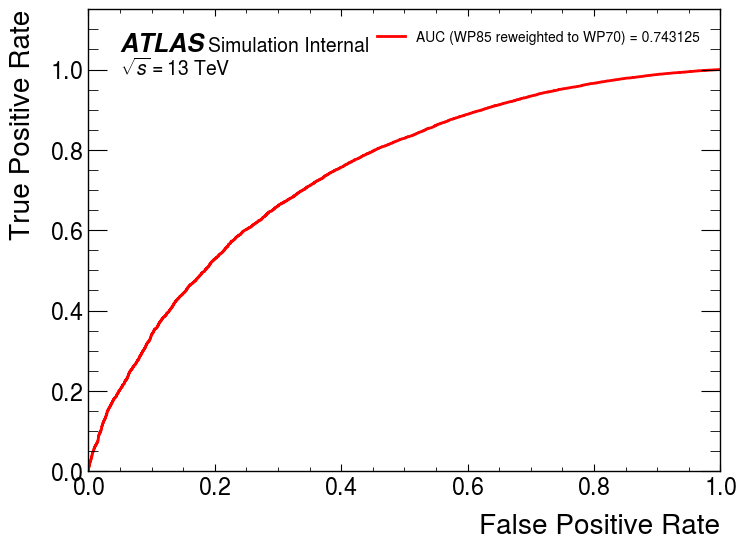

In [40]:
# Aggregate AUC 

scores_85_reweighted_3class = np.concatenate([results_sig, results_bkg])
y_85_reweighted_3class = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr_85_reweighted_3class, tpr_85_reweighted_3class, thresholds_85_reweighted_3class = metrics.roc_curve(y_85_reweighted_3class, scores_85_reweighted_3class, pos_label=1)
AUC_85_reweighted_3class = metrics.roc_auc_score(y_85_reweighted_3class, scores_85_reweighted_3class)

plt.plot(fpr_85_reweighted_3class,tpr_85_reweighted_3class,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted_3class:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
#np.savez('roc_data_85_reweighted_perprocess_3class.npz', fpr=fpr_85_reweighted_3class, tpr=tpr_85_reweighted_3class, thresholds=thresholds_85_reweighted_3class, auc=AUC_85_reweighted_3class)
#print("Data saved to 'roc_data_85_reweighted_perprocess_3class.npz'")

In [34]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

# KS test - 3 classes separated

[0.    0.42  0.623 1.   ]
-----------------------------------------------
0.5313675339543386 1.6825903112907572
0.5203812436384033 1.5790731247104637
4 3 3 3
Signal train histogram: [0.53136753 1.68259031 1.15453525]
Signal test histogram: [0.52038124 1.57907312 1.22251468]
Background 1 train histogram: [1.25098994 1.63899542 0.37630811]
Background 1 test histogram: [1.18002717 1.50833423 0.5257208 ]
Background 2 train histogram: [1.20542389 1.57541864 0.46130499]
Background 2 test histogram: [1.27915576 1.36234168 0.49389714]
-----------------------------------------------

Signal train errors: [0.03255976 0.0401402  0.04516903]
Signal test errors: [0.01866606 0.02249146 0.02687277]
Background 1 train errors: [0.46450314 0.2588964  0.13946703]
Background 1 test errors: [0.19060962 0.14434974 0.13838154]
Background 2 train errors: [0.54294676 0.38389832 0.25455192]
Background 2 test errors: [0.3100433  0.22069262 0.18478365]
-----------------------------------------------

Sig ratio:  

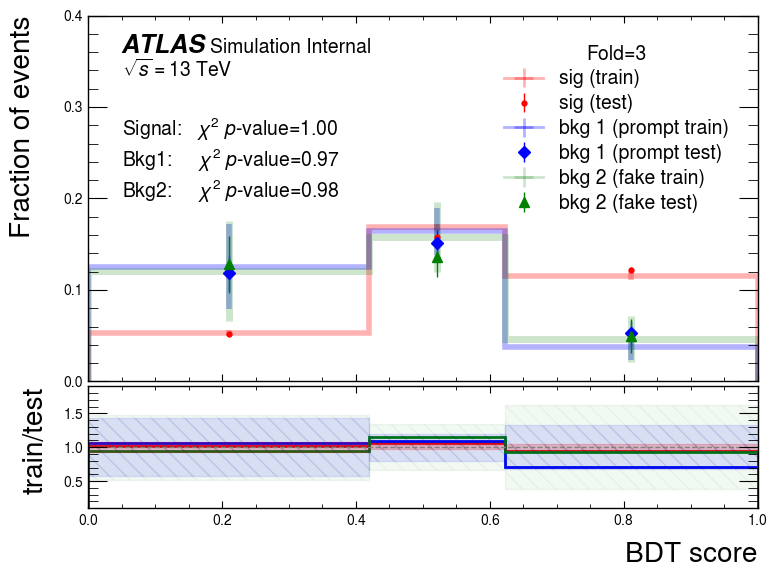

In [39]:
## !!!! KS test with fitted bins 


# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.623, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg1_fold_test = results_bkg_prompts[df_bkg_prompt_85_reweighted['eventNumber']%folds == fold]
results_bkg2_fold_test = results_bkg_fakes[df_bkg_fakes_85_reweighted['eventNumber']%folds == fold]

weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg1_fold_test = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%folds == fold]
weights_bkg2_fold_test = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%folds == fold]

y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg1_fold_test), np.zeros_like(results_bkg2_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg1_fold_test, results_bkg2_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg1_fold_test, weights_bkg2_fold_test])




results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg1_fold_train = results_bkg_prompts[df_bkg_prompt_85_reweighted['eventNumber']%folds != fold]
results_bkg2_fold_train = results_bkg_fakes[df_bkg_fakes_85_reweighted['eventNumber']%folds != fold]

weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg1_fold_train = df_bkg_prompt_85_reweighted['weight'][df_bkg_prompt_85_reweighted['eventNumber']%folds != fold]
weights_bkg2_fold_train = df_bkg_fakes_85_reweighted['weight'][df_bkg_fakes_85_reweighted['eventNumber']%folds != fold]

y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg1_fold_train), np.zeros_like(results_bkg2_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg1_fold_train, results_bkg2_fold_train])
weights = np.concatenate([weights_sig_fold_train, weights_bkg1_fold_train, weights_bkg2_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg1_train, bb = np.histogram(results_bkg1_fold_train, weights=weights_bkg1_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg1_train = len(results_bkg1_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg1_fold_train, weights=weights_bkg1_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg1_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 1 (prompt train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg1_train_e = np.sqrt(sumW2)


bc_bkg1_test, bb = np.histogram(results_bkg1_fold_test,  weights=weights_bkg1_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg1_test = len(results_bkg1_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg1_fold_test, weights=weights_bkg1_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg1_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 1 (prompt test)', histtype='errorbar', ax=axes[0], color='blue', markersize=6, marker='D')
bc_bkg1_test_e = np.sqrt(sumW2)



bc_bkg2_train, bb = np.histogram(results_bkg2_fold_train, weights=weights_bkg2_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg2_train = len(results_bkg2_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg2_fold_train, weights=weights_bkg2_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg2_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 2 (fake train)', histtype='step', ax=axes[0], color='green', alpha=0.2, linewidth=5)
bc_bkg2_train_e = np.sqrt(sumW2)


bc_bkg2_test, bb = np.histogram(results_bkg2_fold_test,  weights=weights_bkg2_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg2_test = len(results_bkg2_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg2_fold_test, weights=weights_bkg2_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg2_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg 2 (fake test)', histtype='errorbar', ax=axes[0], color='green', markersize=7, marker='^')
bc_bkg2_test_e = np.sqrt(sumW2)




print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg1_train), len(bc_bkg2_train))
bc_bkg1_test = np.where(bc_bkg1_test == 0, 1e-1, bc_bkg1_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg1 = np.sum(bc_bkg1_train)/np.sum(bc_bkg1_test)
chi2_bkg1, p_bkg1 = chisquare(bc_bkg1_train, bc_bkg1_test*corr_factor_bkg1)
corr_factor_bkg2 = np.sum(bc_bkg2_train)/np.sum(bc_bkg2_test)
chi2_bkg2, p_bkg2 = chisquare(bc_bkg2_train, bc_bkg2_test*corr_factor_bkg2)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.0,s=F'Signal:   $\chi^2$ $p$-value={p_sig:.2f}\nBkg1:     $\chi^2$ $p$-value={p_bkg1:.2f}\nBkg2:     $\chi^2$ $p$-value={p_bkg2:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background 1 train histogram:", bc_bkg1_train)
print("Background 1 test histogram:", bc_bkg1_test)
print("Background 2 train histogram:", bc_bkg2_train)
print("Background 2 test histogram:", bc_bkg2_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background 1 train errors:", bc_bkg1_train_e)
print("Background 1 test errors:", bc_bkg1_test_e)
print("Background 2 train errors:", bc_bkg2_train_e)
print("Background 2 test errors:", bc_bkg2_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg1 = np.where(bc_bkg1_test == 0, 1, bc_bkg1_train / bc_bkg1_test)
ratio_bkg2 = np.where(bc_bkg2_test == 0, 1, bc_bkg2_train / bc_bkg2_test)

print("\nSig ratio: ", ratio_sig)
print("Bkg 1 ratio: ", ratio_bkg1)
print("Bkg 2 ratio: ", ratio_bkg2)

ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg1_e = np.sqrt((bc_bkg1_train/(1.0*bc_bkg1_test*bc_bkg1_test))*(bc_bkg1_train/(1.0*bc_bkg1_test*bc_bkg1_test))*bc_bkg1_test_e*bc_bkg1_test_e+(1/(1.0*bc_bkg1_test))*(1/(1.0*bc_bkg1_test))*bc_bkg1_train_e*bc_bkg1_train_e)
ratio_bkg2_e = np.sqrt((bc_bkg2_train/(1.0*bc_bkg2_test*bc_bkg2_test))*(bc_bkg2_train/(1.0*bc_bkg2_test*bc_bkg2_test))*bc_bkg2_test_e*bc_bkg2_test_e+(1/(1.0*bc_bkg2_test))*(1/(1.0*bc_bkg2_test))*bc_bkg2_train_e*bc_bkg2_train_e)


print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg1 = np.clip(ratio_bkg1_e, 0, max_error)
clipped_errors_bkg2 = np.clip(ratio_bkg2_e, 0, max_error)


print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg1)
print("Clipped errors:", clipped_errors_bkg2)

custom_bins = np.array([0, 0.420, 0.623, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg1, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)
mplhep.histplot(ratio_bkg2, custom_bins, histtype='step', ax=axes[1], color='green', linewidth=2)


#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.2, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg1, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg2, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='green', alpha=0.05, edgecolor='green', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedbins_splitbackground.png')

# KS test - Bkg classes combined

[0.    0.42  0.623 1.   ]
-----------------------------------------------
0.5303835381742171 1.6422745793297435
0.523303409030995 1.6997449646294043
4 3 3
Signal train histogram: [0.53038354 1.64227458 1.17734002]
Signal test histogram: [0.52330341 1.69974496 1.15428207]
Background train histogram: [1.48161904 1.22105077 0.34442094]
Background test histogram: [1.48890784 1.22982912 0.33157399]
-----------------------------------------------

Signal train errors: [0.03254836 0.03968342 0.04562188]
Signal test errors: [0.01868595 0.02328791 0.02609676]
Background train errors: [1.2402264  0.7089907  0.46678334]
Background test errors: [0.93608147 0.35351133 0.29389158]
-----------------------------------------------

Sig ratio:  [1.01352968 0.96618882 1.01997601]
Bkg ratio:  [0.9951046  0.99286214 1.03874535]

Sig Ratio uncertainties per bin:  [0.07196074 0.02683844 0.04575943]
Clipped errors: [0.07196074 0.02683844 0.04575943]
Clipped errors: [1.04175747 0.64327098 1.68211911]
[0.42  0.

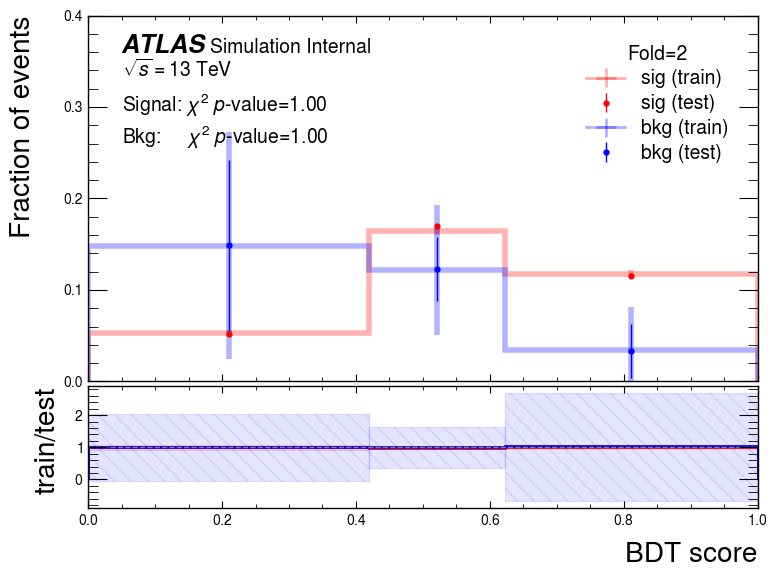

In [44]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.623, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig_85['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg_85['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85['weight'][df_sig_85['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig_85['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg_85['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85['weight'][df_sig_85['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.420, 0.623, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(-0.9,2.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model8_3Class_fittedBins.png')